# Regression Recipe · Predict a number (Miami home prices)
Predict a home's sale price from its size, location and distances. The same recipe works on any table.

**Recipe:** Step 0 processor → 1 settings → 2 look → 3 clean → 4 pick model → 5 split → 6 encode → 7 build → 8 train → 9 score → 10 check → 11 predict your own row → 12 save → 13 app in Colab → 14 shareable web app → 15 permanent app.
Only Step 1 changes between datasets.

## Step 0 · Pick the best processor
In Colab open **Runtime → Change runtime type**, choose **T4 GPU** (free) and click **Save**.
If you have Colab Pro you can pick **L4** or **A100** instead; they are faster but use compute units.

Then run the cell below. It tells you which processor you got. Small tables train fine on a CPU,
so if Colab has no free GPU right now, keep going.

In [ ]:
import tensorflow as tf
gpus = tf.config.list_physical_devices("GPU")
print("TensorFlow", tf.__version__)
print("Processor:", "GPU ✅ " + gpus[0].name if gpus else "CPU only (Runtime → Change runtime type → T4 GPU)")

TensorFlow 2.21.0
Processor: GPU ✅ /physical_device:GPU:0


## Step 1 · Settings (the only cell you change)
* `DATA_URL`: a link to a CSV file (or the name of a file you uploaded).
* `TARGET`: the column you want to predict.
* `PROBLEM`: leave `"auto"` and Step 4 decides; or force `"regression"`, `"binary"` or `"multiclass"`.
* `DROP`: columns to throw away, such as IDs or anything that gives away the answer.
* `SEP`: the character between columns.

In [ ]:
DATA_URL = "https://raw.githubusercontent.com/fenago/datasets/main/miami-housing.csv"
TARGET = "SALE_PRC"     # the column you want to predict
PROBLEM = "auto"        # or "regression", "binary", "multiclass"
DROP = ['PARCELNO']    # columns you know are useless or leak the answer (optional)
SEP = ","               # use ";" or "\t" if your file isn't comma-separated

## Step 2 · Load the data and look at it
Reads the file at `DATA_URL` into a table (a pandas *DataFrame* called `df`), prints its size and shows the first 5 rows.

> 🤔 **Think:** What does one row stand for? Which column is the answer you want to predict?

In [ ]:
import numpy as np
import pandas as pd

df = pd.read_csv(DATA_URL, sep=SEP)
print(f"{df.shape[0]:,} rows × {df.shape[1]} columns")
df.head()

A quick health check of every column: its type, how much is missing, and how many different values it has.

> 🤔 **Think:** Which columns have gaps? Does any column look like an ID, or like something you'd only know *after* the answer (a leak)? Put those in `DROP`.

In [ ]:
pd.DataFrame({
    "type": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing %": (df.isna().mean() * 100).round(1),
    "unique values": df.nunique(),
})

## Step 3 · Clean it (works on any table)
These rules are safe for almost every dataset, so you never have to edit this cell:

1. Drop the columns you listed in `DROP`.
2. Trim spaces in text and treat blanks, `?`, `NA` and `null` as missing.
3. Turn numbers stored as text (like `"$1,200"`) into real numbers.
4. Drop rows with no answer in the target column.
5. Drop exact duplicate rows.
6. Drop columns that can't help: more than half empty, the same value in every row, or an ID that is different in every row.

Missing values that are left get filled in Step 6, using the training rows only.

> 🤔 **Think:** Read the log it prints. Did it drop a column you actually need, or keep one that is really an ID? Fix it with `DROP` in Step 1 and run again.

In [ ]:
df = df.copy()
df.columns = df.columns.str.strip()
log = []

df = df.drop(columns=[c for c in DROP if c in df.columns])
log += [f"dropped {c}: listed in DROP" for c in DROP]

for c in df.select_dtypes(exclude="number").columns:
    s = df[c].astype("string").str.strip().replace({"": pd.NA, "?": pd.NA, "NA": pd.NA, "N/A": pd.NA, "null": pd.NA})
    as_num = pd.to_numeric(s.str.replace(r"[$,%]", "", regex=True), errors="coerce")
    if s.notna().any() and as_num.notna().sum() >= 0.9 * s.notna().sum():
        df[c] = as_num
        log.append(f"converted {c} from text to numbers")
    else:
        df[c] = s.astype(object).where(s.notna(), np.nan)

before = len(df)
df = df.dropna(subset=[TARGET])
log.append(f"dropped {before - len(df)} rows with no {TARGET}")
before = len(df)
df = df.drop_duplicates()
log.append(f"dropped {before - len(df)} duplicate rows")

for c in [c for c in df.columns if c != TARGET]:
    s = df[c]
    if s.isna().mean() > 0.5:
        why = "more than half missing"
    elif s.nunique() <= 1:
        why = "same value in every row"
    elif s.dtype == object and s.nunique() > 0.9 * len(df):
        why = "different in every row (an ID or free text)"
    elif pd.api.types.is_integer_dtype(s) and s.is_unique and (s.sort_values().diff().dropna() == 1).all():
        why = "a row number"
    else:
        continue
    df = df.drop(columns=c)
    log.append(f"dropped {c}: {why}")

print("\n".join(log))
print(f"\nClean table: {df.shape[0]:,} rows × {df.shape[1]} columns")

## Step 4 · Let the recipe pick the kind of model
Looks at the target column and decides which of the three kinds of network to build:
* Target is **numbers with many values** → **regression** (predict a number).
* Target has **two values** → **binary classifier** (yes / no).
* Target has **3+ categories** (text, or whole numbers with 10 or fewer values) → **multi-class classifier**.

Set `PROBLEM` in Step 1 if you want to override the choice.

> 🤔 **Think:** Is the choice right for *your* question? A 1–5 rating could be a number (regression) or 5 categories (multi-class). You decide.

In [ ]:
y_all = df[TARGET]
X_all = df.drop(columns=TARGET)
n_values = y_all.nunique()
is_number = pd.api.types.is_numeric_dtype(y_all) and not pd.api.types.is_bool_dtype(y_all)

if PROBLEM != "auto":
    problem = PROBLEM
elif not is_number or n_values <= 2 or (pd.api.types.is_integer_dtype(y_all) and n_values <= 10):
    problem = "binary" if n_values == 2 else "multiclass"
else:
    problem = "regression"

print(f"Target '{TARGET}' has {n_values} different values → {problem.upper()}")
if problem != "regression":
    print(y_all.value_counts().to_string())

## Step 5 · Split: train, validation, test
Shuffles the rows and cuts them into three groups. For classifiers the split keeps the same share of every class in each group.

* **Train (70%)**: the model learns from these rows.
* **Validation (15%)**: checked after every pass so we know when to stop.
* **Test (15%)**: locked away until the very end, for an honest score.

> 🤔 **Think:** With a small dataset the test set is small too, so the score can swing. How many test rows did you get?

In [ ]:
from sklearn.model_selection import train_test_split

strat = y_all if problem != "regression" else None
X_train, X_rest, y_train_raw, y_rest = train_test_split(X_all, y_all, test_size=0.3, random_state=42, stratify=strat)
X_val, X_test, y_val_raw, y_test_raw = train_test_split(
    X_rest, y_rest, test_size=0.5, random_state=42, stratify=y_rest if strat is not None else None)
print(f"train {len(X_train):,} · validation {len(X_val):,} · test {len(X_test):,}")

## Step 6 · Turn every column into numbers a network can read
* **Number columns:** fill gaps with the median, then scale so every column is on the same scale.
* **Category columns:** fill gaps with the most common value, then one-hot encode (one 0/1 column per category; rare categories are grouped).

This is learned from the **training rows only**, then applied to validation and test, so no answers leak.

> 🤔 **Think:** Why would it be cheating to compute the averages and scales on all rows, including the test rows?

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler

num_cols = X_all.select_dtypes("number").columns.tolist()
cat_cols = [c for c in X_all.columns if c not in num_cols]
prep = ColumnTransformer([
    ("numbers", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num_cols),
    ("categories", make_pipeline(SimpleImputer(strategy="most_frequent"),
        OneHotEncoder(handle_unknown="infrequent_if_exist", max_categories=20, sparse_output=False)), cat_cols),
])
X_tr = prep.fit_transform(X_train).astype("float32")
X_va = prep.transform(X_val).astype("float32")
X_te = prep.transform(X_test).astype("float32")

if problem == "regression":
    y_mean, y_std = y_train_raw.mean(), y_train_raw.std()   # scale the target too; we undo it for the score
    y_tr, y_va, y_te = [((y - y_mean) / y_std).to_numpy("float32") for y in (y_train_raw, y_val_raw, y_test_raw)]
else:
    labels = LabelEncoder().fit(y_all.astype(str))
    y_tr, y_va, y_te = [labels.transform(y.astype(str)) for y in (y_train_raw, y_val_raw, y_test_raw)]
    print("classes:", list(labels.classes_))

print(f"{len(num_cols)} number columns + {len(cat_cols)} category columns → {X_tr.shape[1]} model inputs")

## Step 7 · Build the network (the architecture)
This is the **architecture**: 64 neurons → 20% dropout → 32 neurons → output. `relu` lets each layer learn curves, not just
straight lines; `Dropout` randomly switches off 20% of neurons while training so the network can't just memorize; `Adam` with
`learning_rate=0.001` decides how big each learning step is. `model.summary()` prints every layer and how many weights it will learn.

Same hidden layers every time. Only the **last layer** and the **loss** change with the kind of problem:

| Problem | Last layer | Loss | Score |
|---|---|---|---|
| Regression | 1 neuron, no activation | `mse` | MAE (average error) |
| Binary | 1 neuron, `sigmoid` | `binary_crossentropy` | accuracy |
| Multi-class | 1 neuron per class, `softmax` | `sparse_categorical_crossentropy` | accuracy |

> 🤔 **Think:** Experiment: change 64/32 to 128/64, or add another `Dense` layer. Does the test score in Step 9 get better or worse?

In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(42)
n_classes = 0 if problem == "regression" else len(labels.classes_)
units, activation, loss, metric = {
    "regression": (1, None, "mse", "mae"),
    "binary": (1, "sigmoid", "binary_crossentropy", "accuracy"),
    "multiclass": (n_classes, "softmax", "sparse_categorical_crossentropy", "accuracy"),
}[problem]

model = keras.Sequential([
    keras.Input(shape=(X_tr.shape[1],)),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(32, activation="relu"),
    layers.Dense(units, activation=activation),
])
model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001), loss=loss, metrics=[metric])
model.summary()

## Step 8 · Train it
Early stopping watches the validation loss and stops when it hasn't improved for 15 passes (epochs),
then keeps the best version. That is your guard against overfitting.
Big tables train in batches of 256 rows instead of 32, which is much faster on a GPU.

> 🤔 **Think:** Look at the two lines. If training keeps improving while validation gets worse, the model is memorizing instead of learning (overfitting).

In [ ]:
import matplotlib.pyplot as plt

stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)
BATCH = 32 if len(X_tr) < 5000 else 256
history = model.fit(X_tr, y_tr, validation_data=(X_va, y_va), epochs=300, batch_size=BATCH, callbacks=[stop], verbose=0)

h = pd.DataFrame(history.history)
best = h["val_loss"].idxmin()
print(f"Stopped after {len(h)} epochs. Best epoch: {best + 1}")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
h[["loss", "val_loss"]].plot(ax=ax[0], title="Loss (lower is better)")
h[[metric, "val_" + metric]].plot(ax=ax[1], title=metric)
for a in ax: a.set_xlabel("epoch")
plt.show()

## Step 9 · Score it on the test rows
Now we unlock the test rows for the first time. We also show a **baseline**: what you'd get by always guessing the average
(regression) or the most common class. A useful model has to beat it. The 👉 lines explain the result in plain English.

**How to read the score**

| Number | What it means |
|---|---|
| **MAE** | Average miss, in the target's own units (dollars, kg…). Lower is better. |
| **RMSE** | Like MAE, but big misses count extra. If it's much bigger than MAE, a few predictions are way off. |
| **R²** | How much of the ups and downs the model explains: 0 = no better than guessing the average, 1 = perfect. |
| **Accuracy** | Share of test rows it got right. Only meaningful next to the baseline. |
| **Precision** | When it says "class X", how often it's right. |
| **Recall** | Of all the real "class X" rows, how many it caught. |
| **F1** | One number balancing precision and recall. |
| **Confusion matrix** | Rows are the truth, columns are the prediction. Everything off the diagonal is a mistake. |

> 🔧 **Not good enough? Change the architecture and run again.** Go back to **Step 7** and try more or fewer neurons
> (64 → 128), another `Dense` layer, more or less `Dropout`, or a different `learning_rate`, then use
> **Runtime → Run cell and below**. Change one thing at a time and write down the score each time.
> Notebook **05 · Architecture Harness** does this for you: it trains many designs on the same data and ranks them.

> 🤔 **Think:** Does your model beat the baseline, and by how much? In the confusion matrix, which mistakes does it make, and which ones would be costly in real life?

In [ ]:
from sklearn import metrics as m

if problem == "regression":
    pred = model.predict(X_te, verbose=0).ravel() * y_std + y_mean
    actual = y_test_raw.to_numpy()
    print(f"Average error (MAE): {m.mean_absolute_error(actual, pred):,.2f}")
    print(f"RMSE:                {m.root_mean_squared_error(actual, pred):,.2f}")
    print(f"R² (1.0 is perfect): {m.r2_score(actual, pred):.3f}")
    base = m.mean_absolute_error(actual, np.full_like(actual, y_mean, dtype=float))
    mae, r2 = m.mean_absolute_error(actual, pred), m.r2_score(actual, pred)
    print(f"Baseline MAE (always guess the average): {base:,.2f}\n")
    print(f"👉 On average the model misses by {mae:,.0f}. Always guessing the average misses by {base:,.0f},")
    print(f"   so the model cuts the error by {1 - mae / base:.0%}.")
    print(f"👉 R² = {r2:.2f}: the model explains {max(r2, 0):.0%} of the ups and downs in {TARGET}.")
    plt.figure(figsize=(5, 5))
    plt.scatter(actual, pred, s=6, alpha=0.4)
    lims = [min(actual.min(), pred.min()), max(actual.max(), pred.max())]
    plt.plot(lims, lims, "r--")
    plt.xlabel("actual"); plt.ylabel("predicted"); plt.title("Predicted vs actual (closer to the line is better)")
    plt.show()
else:
    proba = model.predict(X_te, verbose=0)
    pred = (proba.ravel() > 0.5).astype(int) if problem == "binary" else proba.argmax(axis=1)
    acc, base = m.accuracy_score(y_te, pred), np.bincount(y_tr).max() / len(y_tr)
    common = labels.classes_[np.bincount(y_tr).argmax()]
    recall = m.recall_score(y_te, pred, average=None, zero_division=0)
    weak = recall.argmin()
    print(f"Test accuracy: {acc:.3f}")
    print(f"Baseline (always guess the most common class): {base:.3f}\n")
    print(f"👉 Right {acc:.0%} of the time. Always guessing '{common}' would be right {base:.0%} of the time,")
    print(f"   so the model is {(acc - base) * 100:+.0f} points better than guessing.")
    print(f"👉 Weakest class: '{labels.classes_[weak]}'. The model catches only {recall[weak]:.0%} of them (recall).\n")
    print(m.classification_report(y_te, pred, target_names=labels.classes_, zero_division=0))
    m.ConfusionMatrixDisplay.from_predictions(y_te, pred, display_labels=labels.classes_, cmap="Blues", xticks_rotation=45)
    plt.title("Confusion matrix (the diagonal is correct)")
    plt.show()

## Step 10 · Check it on rows it has never seen
Give it rows with the **original columns** (raw values, before cleaning). First, 3 rows from the test set,
so you can compare the prediction with the real answer.

In [ ]:
def predict(rows):
    out = model.predict(prep.transform(rows).astype("float32"), verbose=0)
    if problem == "regression":
        return out.ravel() * y_std + y_mean
    idx = (out.ravel() > 0.5).astype(int) if problem == "binary" else out.argmax(axis=1)
    return labels.classes_[idx]

check = X_test.head(3).copy()
check.insert(0, "actual", y_test_raw.head(3).to_numpy())
check.insert(0, "prediction", predict(X_test.head(3)))
check

## Step 11 · Predict YOUR OWN row
The recipe starts you with a typical row (the middle value of every number column, the most common choice
of every category column). Put the values you want in `MY_VALUES` and run the cell. Any column you leave out keeps its typical value.

> 🤔 **Think:** Change one value at a time (a bigger house, an older patient). Does the prediction move the way common sense says it should?

In [ ]:
typical = {c: (float(X_all[c].median()) if c in num_cols else X_all[c].mode()[0]) for c in X_all.columns}

MY_VALUES = {"TOT_LVG_AREA": 3000, "LND_SQFOOT": 9000, "age": 5}     # ← your values here: {"column name": value, ...}

my_row = pd.DataFrame([{**typical, **MY_VALUES}])
value = predict(my_row)[0]
print("Prediction:", f"{value:,.2f}" if problem == "regression" else value)
my_row

## Step 12 · Save the model
`model.keras` is the network; `prep.joblib` is the cleaning + encoding step. You need both to predict later.

In [ ]:
import joblib

model.save("model.keras")
joblib.dump({"prep": prep, "problem": problem, "labels": None if problem == "regression" else labels,
             "y_mean": y_mean if problem == "regression" else None, "y_std": y_std if problem == "regression" else None,
             "columns": list(X_all.columns), "typical": typical},
            "prep.joblib")
print("Saved model.keras and prep.joblib (Colab: open the 📁 Files panel on the left to download them)")

## Step 13 · A user interface inside Colab
The recipe builds a form from your columns automatically: a number box for every number column and a drop-down for
every category column. Change the values and click **Predict**. Works for any dataset you put through the recipe.

In [ ]:
import ipywidgets as w
from IPython.display import display

style, layout = {"description_width": "180px"}, w.Layout(width="420px")
inputs = {
    c: w.FloatText(value=round(typical[c], 2), description=c, style=style, layout=layout) if c in num_cols
    else w.Dropdown(options=sorted(X_all[c].dropna().astype(str).unique()), value=str(typical[c]), description=c, style=style, layout=layout)
    for c in X_all.columns
}
button, answer = w.Button(description="Predict", button_style="primary"), w.HTML()

def on_click(_):
    row = pd.DataFrame([{c: box.value for c, box in inputs.items()}])
    value = predict(row)[0]
    answer.value = f"<h3>Prediction: {value:,.2f}</h3>" if problem == "regression" else f"<h3>Prediction: {value}</h3>"

button.on_click(on_click)
display(w.VBox([*inputs.values(), button, answer]))

## Step 14 · Optional: a web app you can share (Gradio)
Gradio turns the same form into a real web page. In Colab it prints a **public link** (`https://….gradio.live`)
that anyone can open while this notebook is running (it expires after a few days).

In [ ]:
!pip -q install gradio
import gradio as gr

fields = [
    gr.Number(value=round(typical[c], 2), label=c) if c in num_cols
    else gr.Dropdown(choices=sorted(X_all[c].dropna().astype(str).unique()), value=str(typical[c]), label=c)
    for c in X_all.columns
]

def app(*values):
    value = predict(pd.DataFrame([dict(zip(X_all.columns, values))]))[0]
    return f"{value:,.2f}" if problem == "regression" else str(value)

gr.Interface(app, fields, gr.Textbox(label=f"Predicted {TARGET}"), title=f"Predict {TARGET}",
             flagging_mode="never").launch(share=True)

## Step 15 · Make it a permanent app (with Claude Code)
The Gradio link stops when Colab stops. To keep it running for free, put it on **Hugging Face Spaces**:

1. Download `model.keras` and `prep.joblib` from the 📁 Files panel.
2. Connect the **Hugging Face** connector to Claude (claude.ai → Customize → Connectors), as in the Hugging Face Setup tutorial.
3. Put the two files in a folder, open Claude Code there and prompt:

```text
Use the Hugging Face connector. Create a new Gradio Space called predict-my-data.
Write app.py that loads model.keras (Keras 3) and prep.joblib (a dict with prep, problem,
labels, y_mean, y_std, columns, typical) and shows one input per column, prefilled with
"typical", plus a Predict button. Undo the y scaling for regression and decode labels for
classifiers. Add requirements.txt (tensorflow, scikit-learn, pandas, joblib, gradio),
upload the files and give me the Space URL.
```

Other ways to build a UI: **Streamlit** (a Python web page, also free on Hugging Face Spaces or Streamlit Community Cloud),
or ask Claude Code for a **Netlify** site that calls your Space's API.

## Your turn · Run this recipe on ANY dataset
This notebook is a recipe, not a one-off. Find a table you care about and feed it through:

* **Kaggle Datasets**: https://www.kaggle.com/datasets (download the CSV)
* **OpenML**: https://www.openml.org/search?type=data
* **UCI Machine Learning Repository**: https://archive.ics.uci.edu
* **Data.gov** or your city's open-data portal: https://catalog.data.gov
* **Google Dataset Search**: https://datasetsearch.research.google.com
* **Your own spreadsheet**: Excel or Google Sheets → File → Download → CSV

**Get it into Colab:** for a file on GitHub, click **Raw** and paste that link into `DATA_URL`.
For a downloaded file, click the 📁 Files panel on the left, upload it, and set `DATA_URL = "yourfile.csv"`.

**Before you run, check:** one row per thing · one column is the answer (`TARGET`) · IDs and leaks go in `DROP` ·
a few hundred rows or more. Then change only Step 1 and click **Runtime → Run all**.

**Practice datasets that are known to work:**

| Dataset | `DATA_URL` | `TARGET` | Kind |
|---|---|---|---|
| Miami housing | `https://raw.githubusercontent.com/fenago/datasets/main/miami-housing.csv` | `SALE_PRC` | regression |
| Diamonds | `https://raw.githubusercontent.com/mwaskom/seaborn-data/master/diamonds.csv` | `price` | regression |
| Heart disease | `https://raw.githubusercontent.com/fenago/deep-learning-essentials/main/HeartDiseaseTrain-Test.csv` | `target` | binary |
| Mushrooms | `https://raw.githubusercontent.com/fenago/datasets/main/mushrooms.csv` | `class` | binary |
| Titanic | `https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv` | `Survived` | binary |
| Penguins | `https://raw.githubusercontent.com/mwaskom/seaborn-data/master/penguins.csv` | `species` | multi-class |
| Iris | `https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv` | `species` | multi-class |

#HOMEWORK

##Palmer Penguins

For this part I wanted a dataset that I could use for more than just regression.
I picked Palmer Penguins. It has 344 penguins from three islands in Antarctica, measured from 2007 to 2009.

The columns are species, island, bill length, bill depth, flipper length, body mass, sex and year.

I used it four ways:
1. Regression: predict body mass (body_mass_g).
2. Binary classification: predict if a penguin is male or female.
3. Multi-class classification: predict the species (Adelie, Chinstrap or Gentoo).
4. Clustering: see if K-means can find the species without being told.

## Step 16 - Load the penguin data
Two penguins have no measurements at all, and 11 are missing sex.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PENGUIN_URL = "https://raw.githubusercontent.com/allisonhorst/palmerpenguins/main/inst/extdata/penguins.csv"
pg = pd.read_csv(PENGUIN_URL)
print(pg.shape[0], "rows,", pg.shape[1], "columns")
print("Missing:", pg.isna().sum()[pg.isna().sum() > 0].to_dict())
print(pg["species"].value_counts())
pg.head()

344 rows, 8 columns
Missing: {'bill_length_mm': 2, 'bill_depth_mm': 2, 'flipper_length_mm': 2, 'body_mass_g': 2, 'sex': 11}
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


I plotted the penguins to see if the species look different. Gentoo stand out because they're heavier and have longer flippers.
Adelie and Chinstrap overlap on weight, but bill length separates them.

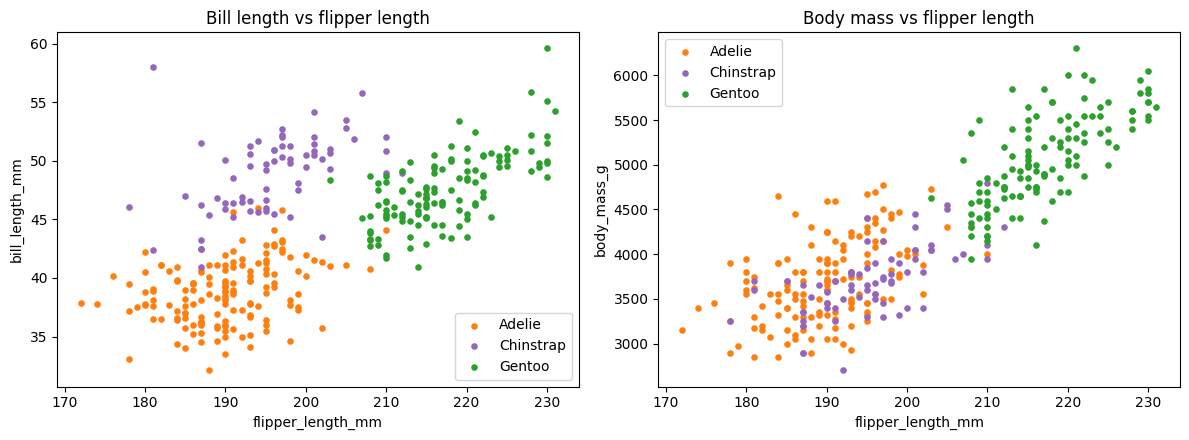

In [2]:
colors = {"Adelie": "tab:orange", "Chinstrap": "tab:purple", "Gentoo": "tab:green"}
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for sp, part in pg.groupby("species"):
    ax[0].scatter(part["flipper_length_mm"], part["bill_length_mm"], s=14, c=colors[sp], label=sp)
    ax[1].scatter(part["flipper_length_mm"], part["body_mass_g"], s=14, c=colors[sp], label=sp)
ax[0].set(xlabel="flipper_length_mm", ylabel="bill_length_mm", title="Bill length vs flipper length")
ax[1].set(xlabel="flipper_length_mm", ylabel="body_mass_g", title="Body mass vs flipper length")
ax[0].legend()
ax[1].legend()
plt.tight_layout()
plt.show()

## Step 17 - Clean the data
- I dropped the 2 penguins with no measurements.
- I dropped year because it's when the penguin was measured, not something about the penguin.
- I kept the penguins with missing sex for now. The missing values get filled in during training.
  In Step 21 I drop them because there sex is what I'm predicting.

In [3]:
pg = pg.dropna(subset=["body_mass_g"]).drop(columns=["year"]).reset_index(drop=True)
print(len(pg), "penguins left, still missing sex:", pg["sex"].isna().sum())
pg.describe().round(1)

342 penguins left, still missing sex: 9


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.0,342.0,342.0,342.0
mean,43.9,17.2,200.9,4201.8
std,5.5,2.0,14.1,802.0
min,32.1,13.1,172.0,2700.0
25%,39.2,15.6,190.0,3550.0
50%,44.4,17.3,197.0,4050.0
75%,48.5,18.7,213.0,4750.0
max,59.6,21.5,231.0,6300.0


## Step 18 - Setup for comparing models
make_prep does the same thing as Step 6: fill missing values, scale numbers and one-hot encode text.
I put it in a pipeline with each model so it only learns from the training rows.

There are only 342 penguins, so one test set would only be about 68 rows and the score would change a lot depending on the split.
So I used 5-fold cross-validation. The data is split into 5 parts, and each part gets a turn as the test set.
The tables show the average score and the +/- (how much it changed between the 5 tries).

In [4]:
import warnings
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, cross_validate, KFold, StratifiedKFold
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn import metrics as m
warnings.filterwarnings("ignore")

def make_prep(X):
    nums = X.select_dtypes("number").columns.tolist()
    cats = [c for c in X.columns if c not in nums]
    return ColumnTransformer([
        ("numbers", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), nums),
        ("categories", make_pipeline(SimpleImputer(strategy="most_frequent"),
                                     OneHotEncoder(handle_unknown="ignore")), cats),
    ])

def pipe_for(model, X):
    return Pipeline([("prep", make_prep(X)), ("model", model)])

def compare(models, X, y, scoring, classification):
    # 5-fold cross-validation for every model, returns a table sorted best first
    if classification:
        cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    else:
        cv = KFold(n_splits=5, shuffle=True, random_state=42)
    rows = {}
    for name, model in models.items():
        res = cross_validate(pipe_for(model, X), X, y, cv=cv, scoring=scoring)
        row = {}
        for label in scoring:
            vals = res["test_" + label]
            if label in ("MAE", "RMSE"):
                vals = -vals
            row[label] = vals.mean()
            row[label + " +/-"] = vals.std()
        rows[name] = row
        print("done:", name)
    table = pd.DataFrame(rows).T
    first = list(scoring)[0]
    return table.sort_values(first, ascending=first in ("MAE", "RMSE"))

## Step 19 - Regression: predict body mass
I used species, island, sex and the other three measurements to predict body_mass_g. I tried 7 models:
- Linear regression: fits a straight line (flat surface) through the data.
- Ridge: linear regression that keeps the weights small so it overfits less.
- KNN: averages the weight of the 7 most similar penguins.
- Decision tree: asks yes/no questions until it gets to an answer.
- Random forest: a lot of trees averaged together.
- Gradient boosting: trees built one after another, each fixing the last one's mistakes.
- Neural network (MLP): like the one in Part 1. I scaled the target for it like Part 1 does.

In [5]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.compose import TransformedTargetRegressor

X_reg = pg.drop(columns=["body_mass_g"])
y_reg = pg["body_mass_g"]

reg_models = {
    "Linear regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "KNN (k=7)": KNeighborsRegressor(n_neighbors=7),
    "Decision tree": DecisionTreeRegressor(max_depth=4, random_state=42),
    "Random forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=42),
    "Gradient boosting": GradientBoostingRegressor(n_estimators=150, max_depth=2, learning_rate=0.05, random_state=42),
    "Neural network (MLP)": TransformedTargetRegressor(
        MLPRegressor(hidden_layer_sizes=(32, 16), alpha=0.01, max_iter=3000, random_state=42),
        transformer=StandardScaler()),
}
reg_table = compare(reg_models, X_reg, y_reg,
                    {"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error", "R2": "r2"},
                    classification=False)
baseline = (y_reg - y_reg.mean()).abs().mean()
print("\nBaseline MAE (always guess the average weight):", round(baseline), "g")
reg_table.round(3)

done: Linear regression
done: Ridge
done: KNN (k=7)
done: Decision tree
done: Random forest
done: Gradient boosting
done: Neural network (MLP)

Baseline MAE (always guess the average weight): 676 g


,MAE,MAE +/-,RMSE,RMSE +/-,R2,R2 +/-
Linear regression,232.704,18.366,293.612,17.983,0.862,0.023
Ridge,233.297,17.767,293.888,17.898,0.862,0.021
Neural network (MLP),234.270,6.674,297.684,10.186,0.858,0.022
Gradient boosting,237.134,12.845,301.681,18.019,0.854,0.027
KNN (k=7),241.416,16.450,306.884,22.776,0.848,0.038
Random forest,244.192,15.994,306.797,18.404,0.849,0.032
Decision tree,257.873,21.007,327.797,26.225,0.826,0.045


Linear regression did the best. Its guesses were off by about 233 g on average. Most of the other models scored about the same. The decision tree did the worst. I think linear regression did well because bigger penguins weigh more, so a straight line fits the data well.

Below I split the data once (80/20) just to make plots.

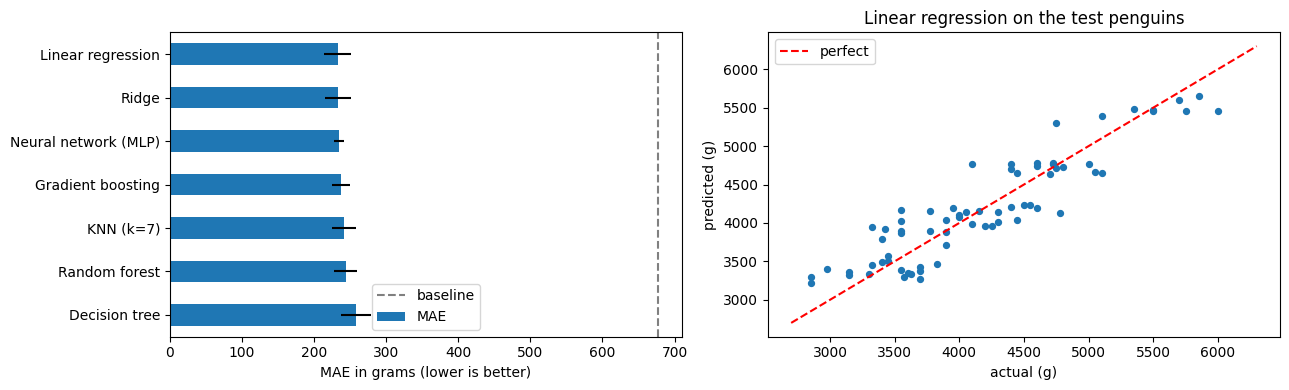

Best model: Linear regression - average error 233 g


In [6]:
best_reg = reg_table.index[0]
Xr_train, Xr_test, yr_train, yr_test = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)
best_reg_pipe = pipe_for(reg_models[best_reg], X_reg).fit(Xr_train, yr_train)
pred = best_reg_pipe.predict(Xr_test)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
reg_table["MAE"].plot.barh(ax=ax[0], xerr=reg_table["MAE +/-"])
ax[0].axvline(baseline, ls="--", c="gray", label="baseline")
ax[0].set_xlabel("MAE in grams (lower is better)")
ax[0].invert_yaxis()
ax[0].legend()
ax[1].scatter(yr_test, pred, s=18)
lims = [y_reg.min(), y_reg.max()]
ax[1].plot(lims, lims, "r--", label="perfect")
ax[1].set(xlabel="actual (g)", ylabel="predicted (g)", title=best_reg + " on the test penguins")
ax[1].legend()
plt.tight_layout()
plt.show()
print("Best model:", best_reg, "- average error", round(reg_table.loc[best_reg, "MAE"]), "g")

## Step 20 - Which columns matter most?
For me species mattered by far the most, then sex. Island barely mattered, probably because species already covers it.

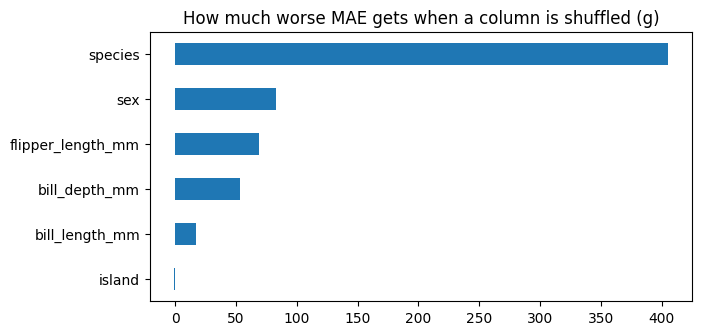

In [7]:
from sklearn.inspection import permutation_importance

imp = permutation_importance(best_reg_pipe, Xr_test, yr_test, n_repeats=20, random_state=42,
                             scoring="neg_mean_absolute_error")
pd.Series(imp.importances_mean, index=Xr_test.columns).sort_values().plot.barh(
    figsize=(7, 3.5), title="How much worse MAE gets when a column is shuffled (g)")
plt.show()

## Step 21 - Binary classification: male or female?
Males are usually bigger, but how much bigger depends on the species, so the model needs both.
I dropped the 9 penguins with no sex recorded.

Besides classification versions of the models above, I added three new ones:
- Logistic regression: a linear model with a sigmoid, so it outputs a probability.
- Naive Bayes: uses probabilities and assumes the columns are independent.
- SVM: finds the boundary with the biggest gap between the two classes.

Scores I looked at:
- Accuracy: percent labeled correctly.
- F1: balances precision and recall.
- ROC AUC: how well it ranks males above females (1 is perfect).

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier

known = pg.dropna(subset=["sex"])
X_bin = known.drop(columns=["sex"])
y_bin = (known["sex"] == "male").astype(int)   # 1 = male, 0 = female

def clf_models():
    return {
        "Logistic regression": LogisticRegression(max_iter=2000),
        "Naive Bayes": GaussianNB(),
        "KNN (k=7)": KNeighborsClassifier(n_neighbors=7),
        "Decision tree": DecisionTreeClassifier(max_depth=4, random_state=42),
        "Random forest": RandomForestClassifier(n_estimators=300, random_state=42),
        "Gradient boosting": GradientBoostingClassifier(random_state=42),
        "SVM": SVC(random_state=42),
        "Neural network (MLP)": MLPClassifier(hidden_layer_sizes=(32, 16), alpha=0.01, max_iter=3000, random_state=42),
    }

bin_models = clf_models()
bin_table = compare(bin_models, X_bin, y_bin, {"accuracy": "accuracy", "F1": "f1_macro", "ROC AUC": "roc_auc"},
                    classification=True)
print("\nBaseline (always guess the more common sex):", round(y_bin.value_counts(normalize=True).max(), 3))
bin_table.round(3)

done: Logistic regression
done: Naive Bayes
done: KNN (k=7)
done: Decision tree
done: Random forest
done: Gradient boosting
done: SVM
done: Neural network (MLP)

Baseline (always guess the more common sex): 0.505


,accuracy,accuracy +/-,F1,F1 +/-,ROC AUC,ROC AUC +/-
SVM,0.919,0.027,0.919,0.027,0.973,0.014
Gradient boosting,0.913,0.032,0.913,0.032,0.971,0.017
Random forest,0.910,0.045,0.910,0.045,0.973,0.015
Neural network (MLP),0.910,0.034,0.910,0.034,0.973,0.017
KNN (k=7),0.904,0.033,0.904,0.033,0.966,0.015
Logistic regression,0.898,0.035,0.898,0.036,0.970,0.015
Decision tree,0.835,0.025,0.834,0.025,0.883,0.039
Naive Bayes,0.703,0.099,0.702,0.100,0.815,0.070


The SVM did best for me at about 92% accuracy, but gradient boosting, random forest, the neural network, KNN and
logistic regression were all between about 90% and 91%. That's within the +/-, so they're really about the same.
Naive Bayes was the worst at about 70%. I think that's because it assumes the measurements are independent,
and for penguins they're not (a big penguin is big in every measurement).

The confusion matrix shows the mistakes, and the ROC curves compare all the models on the same test penguins.
Most of the penguins it got wrong were females that it called male.

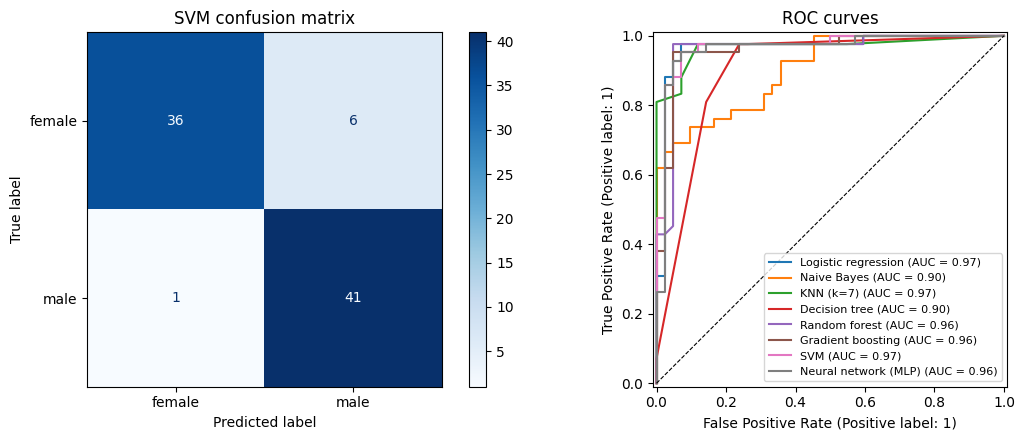

In [9]:
best_bin = bin_table.index[0]
Xb_train, Xb_test, yb_train, yb_test = train_test_split(X_bin, y_bin, test_size=0.25, random_state=42, stratify=y_bin)
bin_fitted = {name: pipe_for(model, X_bin).fit(Xb_train, yb_train) for name, model in bin_models.items()}

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
m.ConfusionMatrixDisplay.from_estimator(bin_fitted[best_bin], Xb_test, yb_test,
                                        display_labels=["female", "male"], cmap="Blues", ax=ax[0])
ax[0].set_title(best_bin + " confusion matrix")
for name, pipe in bin_fitted.items():
    m.RocCurveDisplay.from_estimator(pipe, Xb_test, yb_test, name=name, ax=ax[1])
ax[1].plot([0, 1], [0, 1], "k--", lw=0.8)
ax[1].set_title("ROC curves")
ax[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## Step 22 - Multi-class classification: which species?
For this one I only used the four body measurements. I left out island because Gentoo only live on Biscoe,
so island would give away part of the answer.

There are more Adelie (151) than Chinstrap (68), so I also looked at macro F1, which counts each species equally.

In [10]:
measure = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
X_mc = pg[measure]
y_mc = pg["species"]

mc_models = clf_models()
mc_table = compare(mc_models, X_mc, y_mc, {"accuracy": "accuracy", "F1": "f1_macro"}, classification=True)
print("\nBaseline (always guess Adelie):", round(y_mc.value_counts(normalize=True).max(), 3))
mc_table.round(3)

done: Logistic regression
done: Naive Bayes
done: KNN (k=7)
done: Decision tree
done: Random forest
done: Gradient boosting
done: SVM
done: Neural network (MLP)

Baseline (always guess Adelie): 0.442


,accuracy,accuracy +/-,F1,F1 +/-
Logistic regression,0.988,0.011,0.986,0.013
KNN (k=7),0.985,0.009,0.982,0.011
Neural network (MLP),0.985,0.013,0.982,0.016
SVM,0.982,0.014,0.978,0.018
Random forest,0.977,0.012,0.971,0.014
Gradient boosting,0.974,0.014,0.969,0.018
Naive Bayes,0.974,0.006,0.968,0.007
Decision tree,0.968,0.017,0.964,0.019


Logistic regression on the test penguins:

              precision    recall  f1-score   support

      Adelie       1.00      1.00      1.00        38
   Chinstrap       1.00      1.00      1.00        17
      Gentoo       1.00      1.00      1.00        31

    accuracy                           1.00        86
   macro avg       1.00      1.00      1.00        86
weighted avg       1.00      1.00      1.00        86



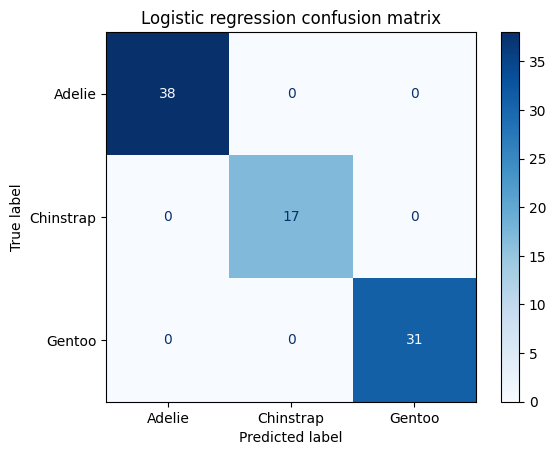

In [11]:
best_mc = mc_table.index[0]
Xm_train, Xm_test, ym_train, ym_test = train_test_split(X_mc, y_mc, test_size=0.25, random_state=42, stratify=y_mc)
mc_pipe = pipe_for(mc_models[best_mc], X_mc).fit(Xm_train, ym_train)
print(best_mc, "on the test penguins:\n")
print(m.classification_report(ym_test, mc_pipe.predict(Xm_test)))
m.ConfusionMatrixDisplay.from_estimator(mc_pipe, Xm_test, ym_test, cmap="Blues")
plt.title(best_mc + " confusion matrix")
plt.show()

This was the easiest problem. Logistic regression got about 99% in cross-validation and every model was above 96%.
I also tried it with only flipper length and body mass, and accuracy dropped to about 82%.
That makes sense from the plot in Step 16, because Adelie and Chinstrap are about the same size. Bill length is what separates them.

## Step 23 - Clustering with K-means
Everything before this was supervised, meaning the model got the answers to learn from.
K-means is unsupervised. It never sees the species and just puts similar penguins into groups.

I clustered on the four scaled measurements. To pick the number of groups (k) I tried 2 to 8 and looked at the
silhouette score (how good a set of cluster is), which is higher when the groups are tight and far apart.

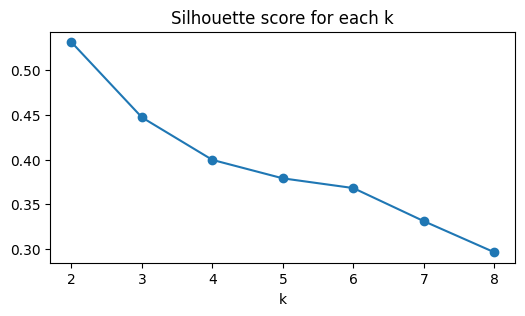

Best k by silhouette: 2


In [12]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

Z = StandardScaler().fit_transform(pg[measure])
scores = {}
for k in range(2, 9):
    labels_k = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(Z)
    scores[k] = silhouette_score(Z, labels_k)
pd.Series(scores).plot(marker="o", figsize=(6, 3), title="Silhouette score for each k")
plt.xlabel("k")
plt.show()
print("Best k by silhouette:", max(scores, key=scores.get))

The silhouette score was highest at k=2. I think that's because Gentoo are very different from the other two,
so "Gentoo vs everyone else" is the most obvious split. I used k=3 anyway since there are 3 species.

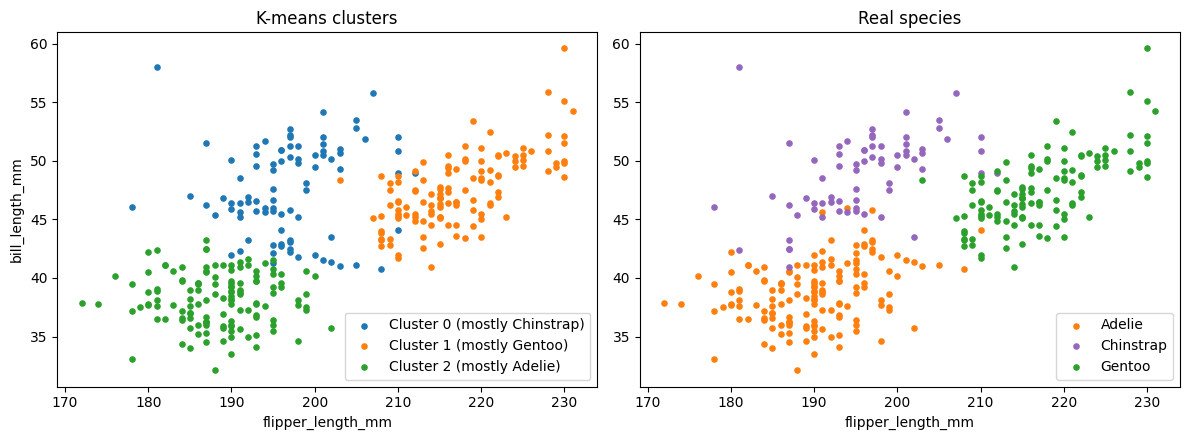

Match with real species (adjusted Rand index, 1 = perfect): 0.79


species,Adelie,Chinstrap,Gentoo
cluster,,,
0,24,63,0
1,0,0,123
2,127,5,0


In [13]:
K = 3
pg["cluster"] = KMeans(n_clusters=K, n_init=10, random_state=42).fit_predict(Z)

# name each cluster after the species that shows up most in it
counts = pd.crosstab(pg["cluster"], pg["species"])
cluster_names = {c: f"Cluster {c} (mostly {counts.loc[c].idxmax()})" for c in counts.index}

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for c, part in pg.groupby("cluster"):
    ax[0].scatter(part["flipper_length_mm"], part["bill_length_mm"], s=14, label=cluster_names[c])
ax[0].set(xlabel="flipper_length_mm", ylabel="bill_length_mm", title="K-means clusters")
ax[0].legend()

for sp, part in pg.groupby("species"):
    ax[1].scatter(part["flipper_length_mm"], part["bill_length_mm"], s=14, c=colors[sp], label=sp)
ax[1].set(xlabel="flipper_length_mm", title="Real species")
ax[1].legend()

plt.tight_layout()
plt.show()

ari = adjusted_rand_score(pg["species"], pg["cluster"])
print("Match with real species (adjusted Rand index, 1 = perfect):", round(ari, 2))
counts

Each row in the table is a cluster and each column is the real species.
K-means put almost all the Gentoo in their own cluster. Most Adelie also got their own cluster,
but about 24 Adelie got grouped with the Chinstrap. The match score was about 0.79, which is pretty good for a model that never saw the labels.

## Step 24 - Summary

In [14]:
summary = pd.DataFrame([
    ["Regression (body mass)", best_reg,
     "MAE " + str(round(reg_table.loc[best_reg, "MAE"])) + " g, R2 " + str(round(reg_table.loc[best_reg, "R2"], 3))],
    ["Binary (male/female)", best_bin,
     "accuracy " + str(round(bin_table.loc[best_bin, "accuracy"], 3)) + ", AUC " + str(round(bin_table.loc[best_bin, "ROC AUC"], 3))],
    ["Multi-class (species)", best_mc,
     "accuracy " + str(round(mc_table.loc[best_mc, "accuracy"], 3)) + ", F1 " + str(round(mc_table.loc[best_mc, "F1"], 3))],
    ["Clustering", "K-means, k=" + str(K), "match with species " + str(round(ari, 2))],
], columns=["question", "best model", "score"]).set_index("question")
summary

,best model,score
question,,
Regression (body mass),Linear regression,"MAE 233 g, R2 0.862"
Binary (male/female),SVM,"accuracy 0.919, AUC 0.973"
Multi-class (species),Logistic regression,"accuracy 0.988, F1 0.986"
Clustering,"K-means, k=3",match with species 0.79


## Step 25 - Save the models


In [15]:
import joblib

# Save your best Palmer Penguins models in a dictionary
penguin_artifacts = {
    "regression_body_mass": best_reg_pipe,              # Best: Linear regression
    "binary_sex_classifier": bin_fitted[best_bin],      # Best: SVM
    "multiclass_species_classifier": mc_pipe,          # Best: Logistic regression
    "kmeans_clustering": pg["cluster"].values          # Cluster assignments
}

joblib.dump(penguin_artifacts, "penguin_models.joblib")
print("Saved penguin_models.joblib (Colab: open the 📁 Files panel on the left to download it)")

Saved penguin_models.joblib (Colab: open the 📁 Files panel on the left to download it)


## Step 26 - Keras network on the penguins
Now I use the same Keras steps as Part 1, but on the penguin data, so I can save it and make an app like Steps 12-14.
The code cells below are the same as Part 1. I only changed the settings here.
TARGET is body_mass_g and I drop the cluster column from Step 23 since it isn't real penguin data.

In [16]:
TARGET = "body_mass_g"
PROBLEM = "regression"
df = pg.drop(columns=["cluster"], errors="ignore").copy()

In [17]:
y_all = df[TARGET]
X_all = df.drop(columns=TARGET)
n_values = y_all.nunique()
is_number = pd.api.types.is_numeric_dtype(y_all) and not pd.api.types.is_bool_dtype(y_all)

if PROBLEM != "auto":
    problem = PROBLEM
elif not is_number or n_values <= 2 or (pd.api.types.is_integer_dtype(y_all) and n_values <= 10):
    problem = "binary" if n_values == 2 else "multiclass"
else:
    problem = "regression"

print(f"Target '{TARGET}' has {n_values} different values → {problem.upper()}")
if problem != "regression":
    print(y_all.value_counts().to_string())

Target 'body_mass_g' has 94 different values → REGRESSION


## Step 27 - Split the data
Same as Step 5: 70% train, 15% validation, 15% test.

In [18]:
from sklearn.model_selection import train_test_split

strat = y_all if problem != "regression" else None
X_train, X_rest, y_train_raw, y_rest = train_test_split(X_all, y_all, test_size=0.3, random_state=42, stratify=strat)
X_val, X_test, y_val_raw, y_test_raw = train_test_split(
    X_rest, y_rest, test_size=0.5, random_state=42, stratify=y_rest if strat is not None else None)
print(f"train {len(X_train):,} · validation {len(X_val):,} · test {len(X_test):,}")

train 239 · validation 51 · test 52


## Step 28 - Turn everything into numbers
Same as Step 6. It's fit on the training rows only.

In [19]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler

num_cols = X_all.select_dtypes("number").columns.tolist()
cat_cols = [c for c in X_all.columns if c not in num_cols]
prep = ColumnTransformer([
    ("numbers", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num_cols),
    ("categories", make_pipeline(SimpleImputer(strategy="most_frequent"),
        OneHotEncoder(handle_unknown="infrequent_if_exist", max_categories=20, sparse_output=False)), cat_cols),
])
X_tr = prep.fit_transform(X_train).astype("float32")
X_va = prep.transform(X_val).astype("float32")
X_te = prep.transform(X_test).astype("float32")

if problem == "regression":
    y_mean, y_std = y_train_raw.mean(), y_train_raw.std()   # scale the target too; we undo it for the score
    y_tr, y_va, y_te = [((y - y_mean) / y_std).to_numpy("float32") for y in (y_train_raw, y_val_raw, y_test_raw)]
else:
    labels = LabelEncoder().fit(y_all.astype(str))
    y_tr, y_va, y_te = [labels.transform(y.astype(str)) for y in (y_train_raw, y_val_raw, y_test_raw)]
    print("classes:", list(labels.classes_))

print(f"{len(num_cols)} number columns + {len(cat_cols)} category columns → {X_tr.shape[1]} model inputs")

3 number columns + 3 category columns → 11 model inputs


## Step 29 - Build the network
Same network as Step 7: 64 neurons -> 20% dropout -> 32 neurons -> 1 output.

In [20]:
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(42)
n_classes = 0 if problem == "regression" else len(labels.classes_)
units, activation, loss, metric = {
    "regression": (1, None, "mse", "mae"),
    "binary": (1, "sigmoid", "binary_crossentropy", "accuracy"),
    "multiclass": (n_classes, "softmax", "sparse_categorical_crossentropy", "accuracy"),
}[problem]

model = keras.Sequential([
    keras.Input(shape=(X_tr.shape[1],)),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(32, activation="relu"),
    layers.Dense(units, activation=activation),
])
model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001), loss=loss, metrics=[metric])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,881 (11.25 KB)

 Trainable params: 2,881 (11.25 KB)

 Non-trainable params: 0 (0.00 B)

## Step 30 - Train
Same as Step 8, with early stopping.

Stopped after 75 epochs. Best epoch: 60


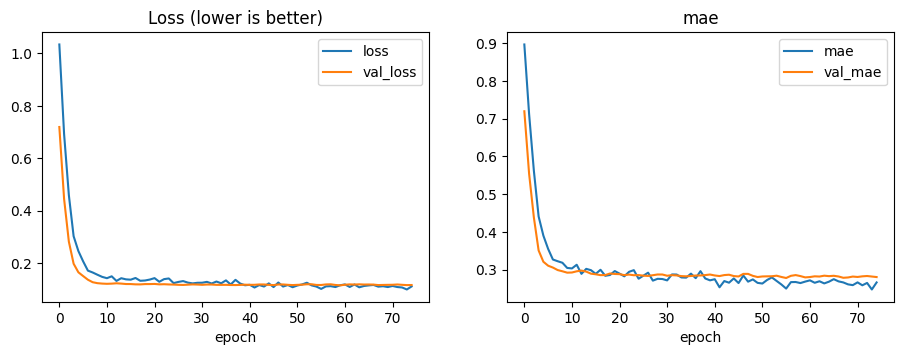

In [21]:
import matplotlib.pyplot as plt

stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)
BATCH = 32 if len(X_tr) < 5000 else 256
history = model.fit(X_tr, y_tr, validation_data=(X_va, y_va), epochs=300, batch_size=BATCH, callbacks=[stop], verbose=0)

h = pd.DataFrame(history.history)
best = h["val_loss"].idxmin()
print(f"Stopped after {len(h)} epochs. Best epoch: {best + 1}")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
h[["loss", "val_loss"]].plot(ax=ax[0], title="Loss (lower is better)")
h[[metric, "val_" + metric]].plot(ax=ax[1], title=metric)
for a in ax: a.set_xlabel("epoch")
plt.show()

## Step 31 - Score on the test rows
Same as Step 9. The test set is only about 52 penguins, so the score can change a lot with a different split.

Average error (MAE): 243.83
RMSE:                315.68
R² (1.0 is perfect): 0.814
Baseline MAE (always guess the average): 604.94

👉 On average the model misses by 244. Always guessing the average misses by 605,
   so the model cuts the error by 60%.
👉 R² = 0.81: the model explains 81% of the ups and downs in body_mass_g.


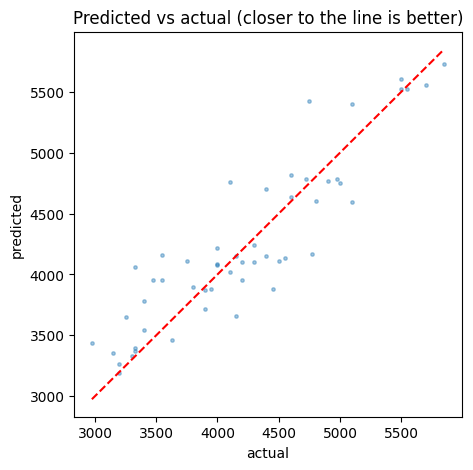

In [22]:
from sklearn import metrics as m

if problem == "regression":
    pred = model.predict(X_te, verbose=0).ravel() * y_std + y_mean
    actual = y_test_raw.to_numpy()
    print(f"Average error (MAE): {m.mean_absolute_error(actual, pred):,.2f}")
    print(f"RMSE:                {m.root_mean_squared_error(actual, pred):,.2f}")
    print(f"R² (1.0 is perfect): {m.r2_score(actual, pred):.3f}")
    base = m.mean_absolute_error(actual, np.full_like(actual, y_mean, dtype=float))
    mae, r2 = m.mean_absolute_error(actual, pred), m.r2_score(actual, pred)
    print(f"Baseline MAE (always guess the average): {base:,.2f}\n")
    print(f"👉 On average the model misses by {mae:,.0f}. Always guessing the average misses by {base:,.0f},")
    print(f"   so the model cuts the error by {1 - mae / base:.0%}.")
    print(f"👉 R² = {r2:.2f}: the model explains {max(r2, 0):.0%} of the ups and downs in {TARGET}.")
    plt.figure(figsize=(5, 5))
    plt.scatter(actual, pred, s=6, alpha=0.4)
    lims = [min(actual.min(), pred.min()), max(actual.max(), pred.max())]
    plt.plot(lims, lims, "r--")
    plt.xlabel("actual"); plt.ylabel("predicted"); plt.title("Predicted vs actual (closer to the line is better)")
    plt.show()
else:
    proba = model.predict(X_te, verbose=0)
    pred = (proba.ravel() > 0.5).astype(int) if problem == "binary" else proba.argmax(axis=1)
    acc, base = m.accuracy_score(y_te, pred), np.bincount(y_tr).max() / len(y_tr)
    common = labels.classes_[np.bincount(y_tr).argmax()]
    recall = m.recall_score(y_te, pred, average=None, zero_division=0)
    weak = recall.argmin()
    print(f"Test accuracy: {acc:.3f}")
    print(f"Baseline (always guess the most common class): {base:.3f}\n")
    print(f"👉 Right {acc:.0%} of the time. Always guessing '{common}' would be right {base:.0%} of the time,")
    print(f"   so the model is {(acc - base) * 100:+.0f} points better than guessing.")
    print(f"👉 Weakest class: '{labels.classes_[weak]}'. The model catches only {recall[weak]:.0%} of them (recall).\n")
    print(m.classification_report(y_te, pred, target_names=labels.classes_, zero_division=0))
    m.ConfusionMatrixDisplay.from_predictions(y_te, pred, display_labels=labels.classes_, cmap="Blues", xticks_rotation=45)
    plt.title("Confusion matrix (the diagonal is correct)")
    plt.show()

## Step 32 - Check some test rows
I run 3 test penguins through the network and put the prediction next to the real weight.

In [23]:
def predict(rows):
    out = model.predict(prep.transform(rows).astype("float32"), verbose=0)
    if problem == "regression":
        return out.ravel() * y_std + y_mean
    idx = (out.ravel() > 0.5).astype(int) if problem == "binary" else out.argmax(axis=1)
    return labels.classes_[idx]

check = X_test.head(3).copy()
check.insert(0, "actual", y_test_raw.head(3).to_numpy())
check.insert(0, "prediction", predict(X_test.head(3)))
check

,prediction,actual,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,sex
177,4762.358898,4100.0,Gentoo,Biscoe,44.5,14.3,216.0,NaN
16,4106.588032,4500.0,Adelie,Torgersen,42.5,20.7,197.0,male
319,3877.711803,4450.0,Chinstrap,Dream,50.8,18.5,201.0,male


## Step 33 - Predict my own penguin
I start from a typical penguin and change a few values. I tried a big male Gentoo.

In [24]:
typical = {c: (float(X_all[c].median()) if c in num_cols else X_all[c].mode()[0]) for c in X_all.columns}

MY_VALUES = {"species": "Gentoo", "sex": "male", "flipper_length_mm": 225}     # ← your values here: {"column name": value, ...}

my_row = pd.DataFrame([{**typical, **MY_VALUES}])
value = predict(my_row)[0]
print("Prediction:", f"{value:,.2f}" if problem == "regression" else value)
my_row

Prediction: 5,365.87


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,sex
0,Gentoo,Biscoe,44.45,17.3,225,male


## Step 34 - Save the model
model.keras is the network and prep.joblib is the cleaning and encoding step. Both are needed to predict later.

In [25]:
import joblib

model.save("model.keras")
joblib.dump({"prep": prep, "problem": problem, "labels": None if problem == "regression" else labels,
             "y_mean": y_mean if problem == "regression" else None, "y_std": y_std if problem == "regression" else None,
             "columns": list(X_all.columns), "typical": typical},
            "prep.joblib")
print("Saved model.keras and prep.joblib (Colab: open the 📁 Files panel on the left to download them)")

Saved model.keras and prep.joblib (Colab: open the 📁 Files panel on the left to download them)


## Step 35 - Simple form in Colab
A form with a box for every column. I change the values and click Predict to get the penguin's weight.

In [26]:
import ipywidgets as w
from IPython.display import display

style, layout = {"description_width": "180px"}, w.Layout(width="420px")
inputs = {
    c: w.FloatText(value=round(typical[c], 2), description=c, style=style, layout=layout) if c in num_cols
    else w.Dropdown(options=sorted(X_all[c].dropna().astype(str).unique()), value=str(typical[c]), description=c, style=style, layout=layout)
    for c in X_all.columns
}
button, answer = w.Button(description="Predict", button_style="primary"), w.HTML()

def on_click(_):
    row = pd.DataFrame([{c: box.value for c, box in inputs.items()}])
    value = predict(row)[0]
    answer.value = f"<h3>Prediction: {value:,.2f}</h3>" if problem == "regression" else f"<h3>Prediction: {value}</h3>"

button.on_click(on_click)
display(w.VBox([*inputs.values(), button, answer]))

## Step 36 - Web app with Gradio (optional)
Same form, but as a web page with a public link. The link only works while the notebook is running.

In [27]:
!pip -q install gradio
import gradio as gr

fields = [
    gr.Number(value=round(typical[c], 2), label=c) if c in num_cols
    else gr.Dropdown(choices=sorted(X_all[c].dropna().astype(str).unique()), value=str(typical[c]), label=c)
    for c in X_all.columns
]

def app(*values):
    value = predict(pd.DataFrame([dict(zip(X_all.columns, values))]))[0]
    return f"{value:,.2f}" if problem == "regression" else str(value)

gr.Interface(app, fields, gr.Textbox(label=f"Predicted {TARGET}"), title=f"Predict {TARGET}",
             flagging_mode="never").launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://9f4b37210b22b1fa36.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
